# siRNA Dataset

### Import Libraries

- paper : https://bmcbioinformatics.biomedcentral.com/articles/10.1186/1471-2105-7-65 
- kaggle:  https://www.kaggle.com/datasets/livtoft/sirna-activity/data
- https://geneontology.org/ 

In [1]:
!pip install shap lime numpy seaborn tensorflow scikit-learn
!pip install --upgrade numpy scikit-learn


Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.2
    Uninstalling numpy-2.1.2:
      Successfully uninstalled numpy-2.1.2
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.1.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.17.0 requires numpy<2.0.0,>=1.23.5; python_version <= "3.11", but you have numpy 2.1.2 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have n

In [18]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns # statistical data visualization
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

### Import Dataset

In [19]:
data = 'siRNA/data.csv'

df_v2 = pd.read_csv(data)


### Exploratory Data Analysis

In [20]:
df_v2.shape

(653, 24)

In [21]:
df_v2.head()

,Target seq,Start,End,Sequence,G,U,bi,uni,duplex,Pos1,...,Pos18,Dif_5-3,Content+,Content-,Cons+,Cons-,Cons_Sum,Hyb19,target,Activity
0,M60857,195,213,AUUAUCCACUGUUUUUGGA,3,9,-7.0,-1.9,-28.1,-1.1,...,-2.4,-1.3,2,6,2,6,4,0.001175,-8.1,24.7
1,M60857,197,215,AAAUUAUCCACUGUUUUUG,2,9,-0.7,0.0,-24.2,-0.9,...,-2.1,-1.2,1,6,1,5,4,0.001175,-8.1,9.8
2,M60857,199,217,CAAAAUUAUCCACUGUUUU,1,8,-1.5,0.0,-24.2,-2.1,...,-0.9,1.2,2,5,3,2,-1,0.001175,-11.4,50.5
3,M60857,201,219,CACAAAAUUAUCCACUGUU,1,6,-0.6,0.0,-26.7,-2.1,...,-0.9,1.2,3,3,3,3,0,0.001175,-14.5,83.7
4,M60857,203,221,GCCACAAAAUUAUCCACUG,2,4,-0.1,0.0,-30.3,-3.4,...,-2.1,1.3,4,2,2,3,1,0.001175,-17.8,60.3


In [22]:
#Columns names

col_names = df_v2.columns

print(col_names)

Index(['Target seq', 'Start', 'End', 'Sequence', 'G', 'U', 'bi', 'uni',
       'duplex', 'Pos1', 'Pos2', 'Pos6', 'Pos13', 'Pos14', 'Pos18', 'Dif_5-3',
       'Content+', 'Content-', 'Cons+', 'Cons-', 'Cons_Sum', 'Hyb19', 'target',
       'Activity'],
      dtype='object')


In [23]:
df_v2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653 entries, 0 to 652
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Target seq  653 non-null    object 
 1   Start       653 non-null    int64  
 2   End         653 non-null    int64  
 3   Sequence    653 non-null    object 
 4   G           653 non-null    int64  
 5   U           653 non-null    int64  
 6   bi          653 non-null    float64
 7   uni         653 non-null    float64
 8   duplex      653 non-null    float64
 9   Pos1        653 non-null    float64
 10  Pos2        653 non-null    float64
 11  Pos6        653 non-null    float64
 12  Pos13       653 non-null    float64
 13  Pos14       653 non-null    float64
 14  Pos18       653 non-null    float64
 15  Dif_5-3     653 non-null    float64
 16  Content+    653 non-null    int64  
 17  Content-    653 non-null    int64  
 18  Cons+       653 non-null    int64  
 19  Cons-       653 non-null    i

In [24]:
#Checking missing values

df_v2.isnull().sum()

Target seq    0
Start         0
End           0
Sequence      0
G             0
U             0
bi            0
uni           0
duplex        0
Pos1          0
Pos2          0
Pos6          0
Pos13         0
Pos14         0
Pos18         0
Dif_5-3       0
Content+      0
Content-      0
Cons+         0
Cons-         0
Cons_Sum      0
Hyb19         0
target        0
Activity      0
dtype: int64

- Correlation Matrix of Features and SiRNA activity

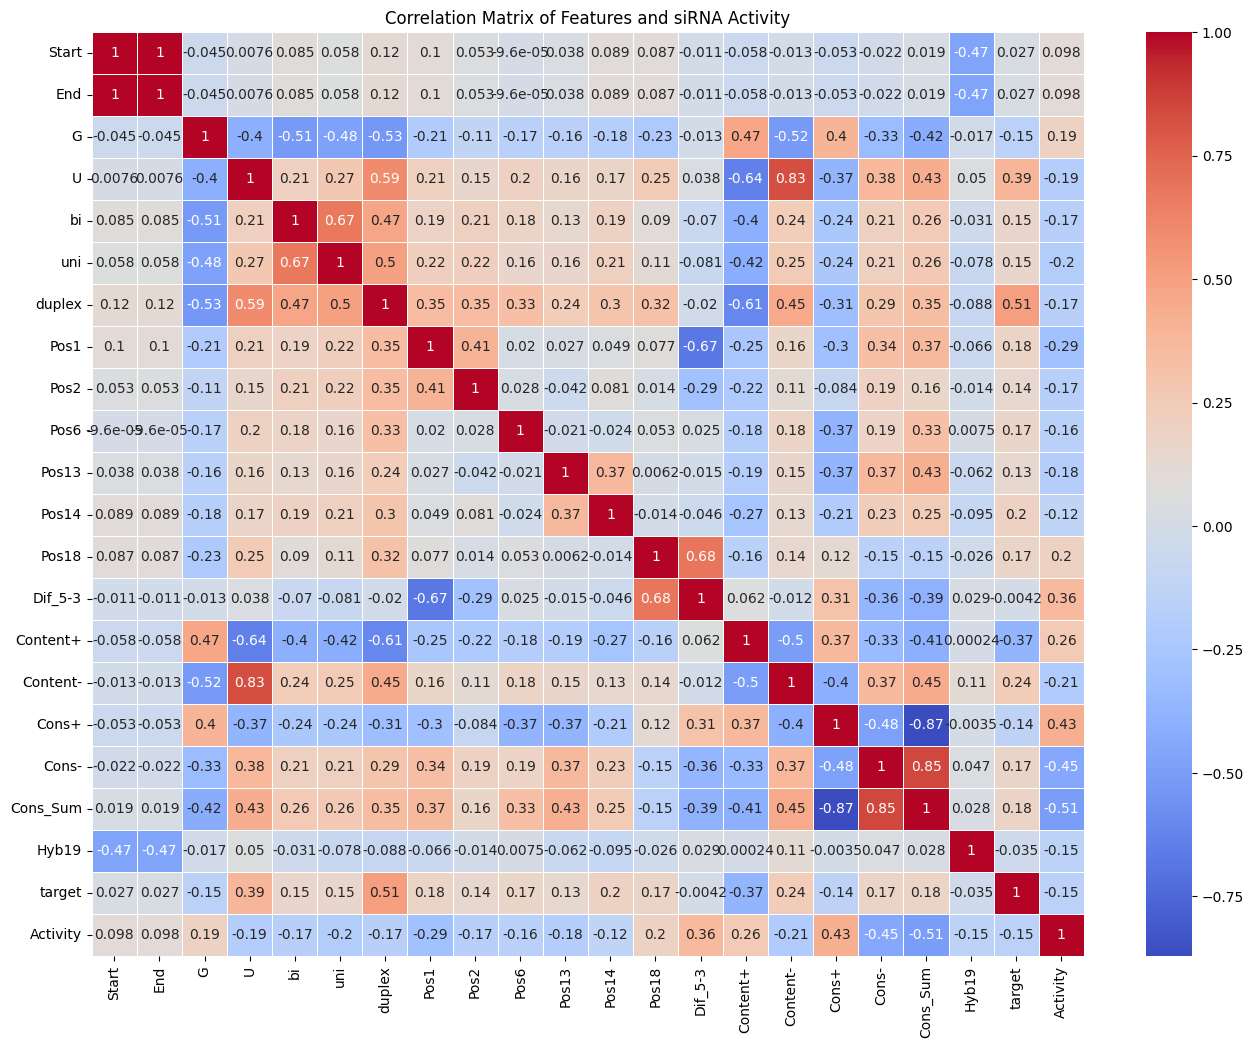

In [26]:
# Selecting only numeric columns to calculate correlation matrix
numeric_df = df_v2.select_dtypes(include=['number'])
correlation_matrix = numeric_df.corr()

# Plot the correlation heatmap to visualize relationships
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Features and siRNA Activity')
plt.show()

- Select features # Selecting features that have a significant correlation with siRNA activity (greater than 0.4 or less than -0.4)
- Plot scatter plots for features with significant correlation with Activity
- Explain:
  - The scatter plots above show the relationship between the features that have significant correlations (greater than 0.4 or less than -0.4) and the siRNA activity. These visualizations help us understand the distribution and patterns between each feature and the target variable.
  - Cons+, Cons and Cons_sum vs Activity
- *About Cons+, Cons and Cons_sum*:
  - 
  - In the context of the siRNA dataset and based on the research paper by Shabalina et al., the features Cons+, Cons-, and Cons_Sum represent different aspects of position-dependent nucleotide preferences and avoidances within the siRNA sequence. These features aim to capture the optimal sequence composition that could influence the efficiency of gene silencing.

Detailed explanation:

Cons+ (Consensus Positive):

This feature represents the number of preferred nucleotides across specific positions in the siRNA antisense strand.
Preferred nucleotides are those that have been found, based on statistical analysis, to correlate positively with efficient gene silencing. These preferences are derived by analyzing large datasets and finding nucleotides that appear more frequently in efficient siRNAs.
For example, a U at the 5' end of the antisense strand is often preferred, which contributes to the value of Cons+.
Cons- (Consensus Negative):

This feature counts the number of avoided nucleotides in specific positions of the siRNA antisense strand.
Avoided nucleotides are those that correlate negatively with silencing efficiency. They are nucleotides that are found less frequently in efficient siRNAs.
For instance, certain nucleotides like G in specific positions might reduce the effectiveness of siRNA, contributing to the Cons- value.
Cons_Sum (Consensus Sum):

This is a combined measure of both Cons+ and Cons-. It is calculated as the difference between Cons+ and Cons-: \text{Cons_Sum} = \text{Cons+} - \text{Cons-}
A higher positive value of Cons_Sum indicates that the sequence has more preferred nucleotides and fewer avoided ones, suggesting a higher likelihood of efficient gene silencing.
On the other hand, a negative value would imply that the sequence has more avoided nucleotides, indicating potentially lower silencing efficiency.
These features are derived through position-specific analyses of a large siRNA dataset. By statistically evaluating which nucleotides are preferred or avoided at each sequence position, researchers developed Cons+, Cons-, and Cons_Sum to summarize these preferences. The features are important for predicting the efficiency of siRNA as they represent sequence characteristics that significantly impact gene silencing success. 


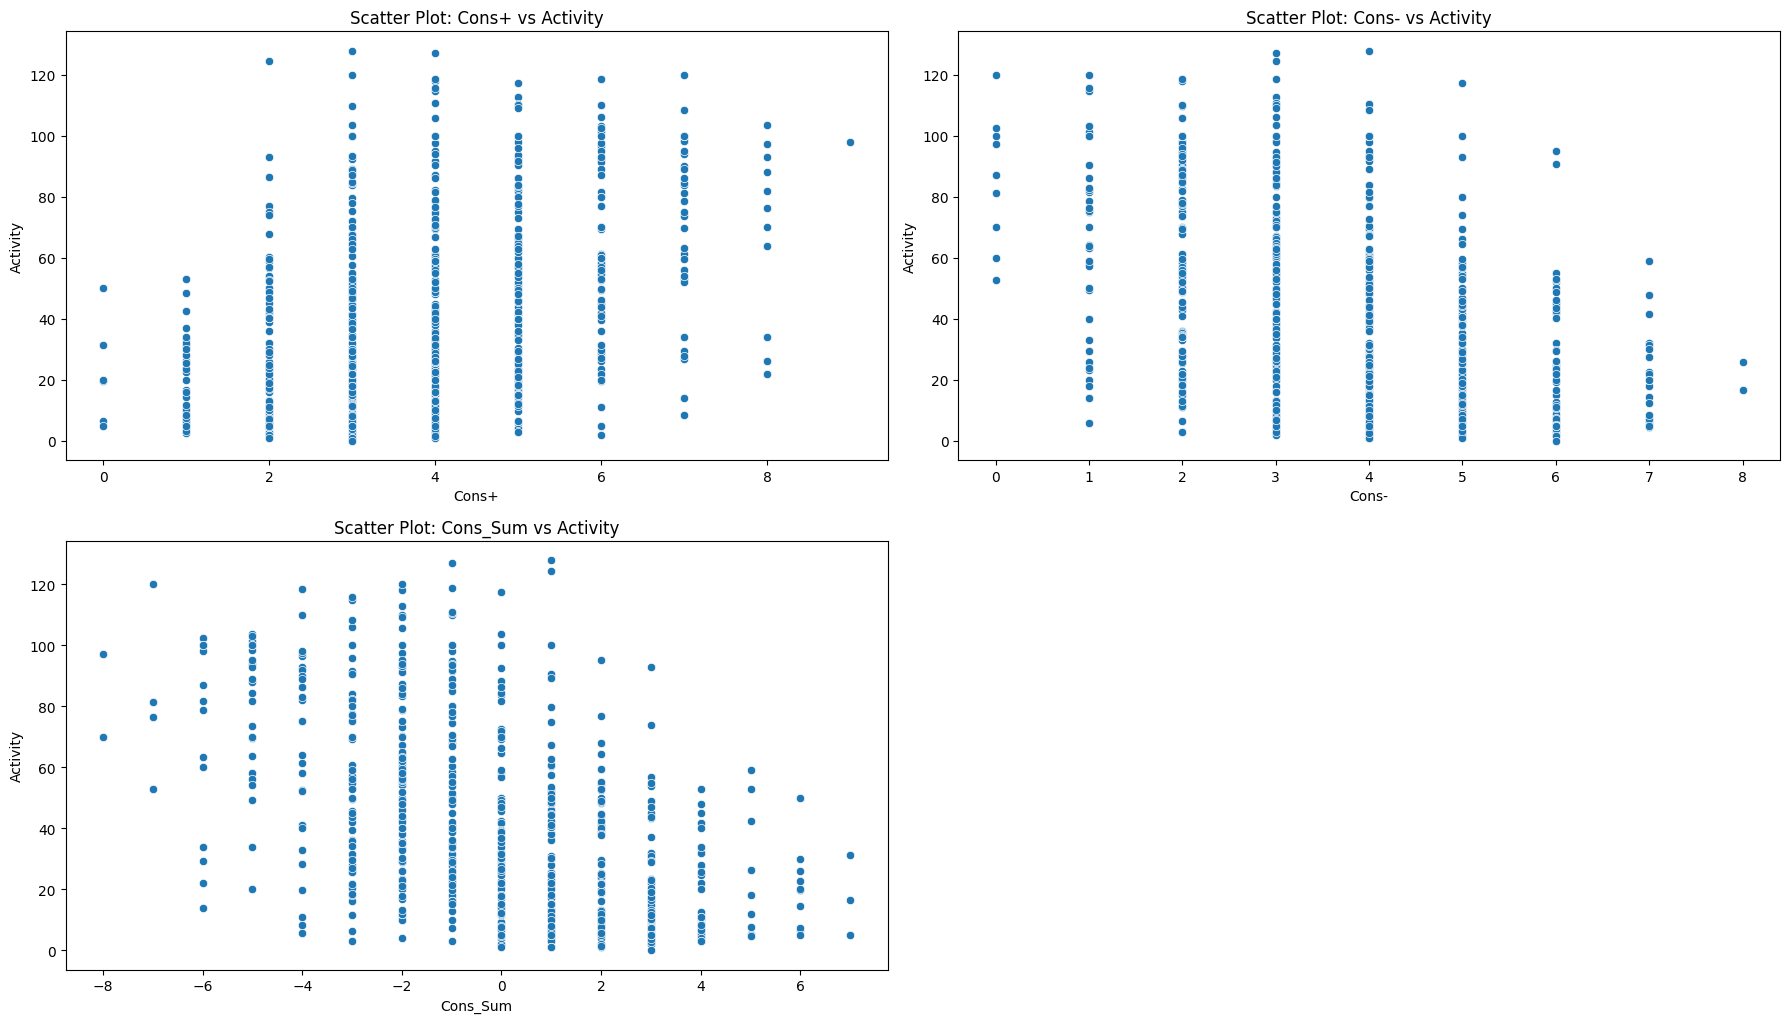

In [28]:
# Selecting features that have a significant correlation with siRNA activity (greater than 0.4 or less than -0.4)
significant_features = correlation_matrix['Activity'][(correlation_matrix['Activity'] > 0.4) | (correlation_matrix['Activity'] < -0.4)].index.tolist()

# Plot scatter plots for features with significant correlation with Activity
plt.figure(figsize=(18, 15))

for i, feature in enumerate(significant_features):
    if feature != 'Activity':  # Skip Activity itself
        plt.subplot(3, 2, i + 1)
        sns.scatterplot(data=df_v2, x=feature, y='Activity')
        plt.title(f'Scatter Plot: {feature} vs Activity')

plt.tight_layout()
plt.show()


- Get Data training X and target y

In [10]:
# Excluding columns that include ID num (to be ıncluded only int.)
df2 = df_v2.drop(['Target seq', 'Sequence'], axis=1)

X = df2.iloc[:, :-1]
y = df2['Activity'] 

# Display first few rows
print(X.head())
print(y.head())

# Summary statistics
print(X.describe())
print(y.describe())

   Start  End  G  U   bi  uni  duplex  Pos1  Pos2  Pos6  ...  Pos14  Pos18  \
0    195  213  3  9 -7.0 -1.9   -28.1  -1.1  -0.9  -3.3  ...   -0.9   -2.4   
1    197  215  2  9 -0.7  0.0   -24.2  -0.9  -0.9  -1.1  ...   -0.9   -2.1   
2    199  217  1  8 -1.5  0.0   -24.2  -2.1  -0.9  -0.9  ...   -2.1   -0.9   
3    201  219  1  6 -0.6  0.0   -26.7  -2.1  -2.2  -0.9  ...   -2.2   -0.9   
4    203  221  2  4 -0.1  0.0   -30.3  -3.4  -3.3  -0.9  ...   -3.3   -2.1   

   Dif_5-3  Content+  Content-  Cons+  Cons-  Cons_Sum     Hyb19  target  
0     -1.3         2         6      2      6         4  0.001175    -8.1  
1     -1.2         1         6      1      5         4  0.001175    -8.1  
2      1.2         2         5      3      2        -1  0.001175   -11.4  
3      1.2         3         3      3      3         0  0.001175   -14.5  
4      1.3         4         2      2      3         1  0.001175   -17.8  

[5 rows x 21 columns]
0    24.7
1     9.8
2    50.5
3    83.7
4    60.3
Name: Ac

#### Import Libraries

* Requirements: **tensorflow**

### Prepare Data for Training, Validation, and Testing: to use on black box models



#### Split Dataset

In [14]:
#split of sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
# Initialize the scaler
#scaler = StandardScaler()

# Fit the scaler on the entire dataset and transform
#X_scaled = scaler.fit_transform(X)
#print(X_scaled)
# Split the dataset into training (70%), validation (15%), and testing (15%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
print(f"Training set: {X_train.shape}, Validation set: {X_val.shape}, Testing set: {X_test.shape}")


Training set: (457, 21), Validation set: (98, 21), Testing set: (98, 21)


## White Box Models-Explainable

#### Linear Regression
- Here, we don use scaling, the dataset is already scaled and normalized.
- From a paper

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm

# Dropping identifier columns like 'Sequence', 'Target seq'
cleaned_data = df_v2.drop(columns=['Sequence', 'Target seq'])

# Selecting numeric features and the target variable for regression analysis again
numeric_features_cleaned = cleaned_data.select_dtypes(include=['number']).drop(columns=['Activity'])
target_cleaned = cleaned_data['Activity']

# Splitting the data into training and testing sets
X_train_cleaned, X_test_cleaned, y_train_cleaned, y_test_cleaned = train_test_split(numeric_features_cleaned, target_cleaned, test_size=0.2, random_state=42)

# Creating and fitting the linear regression model
linear_model_cleaned = LinearRegression()
linear_model_cleaned.fit(X_train_cleaned, y_train_cleaned)

# Making predictions on the test set
y_pred_cleaned = linear_model_cleaned.predict(X_test_cleaned)

# Evaluating the model using suitable metrics
mse_cleaned = mean_squared_error(y_test_cleaned, y_pred_cleaned)
mae_cleaned = mean_absolute_error(y_test_cleaned, y_pred_cleaned)
r2_cleaned = r2_score(y_test_cleaned, y_pred_cleaned)

# Displaying the metrics
print("After Dropping Identifier Columns:")
print("Mean Squared Error (MSE):", mse_cleaned)
print("Mean Absolute Error (MAE):", mae_cleaned)
print("R-squared (R2):", r2_cleaned)

# Using statsmodels to get a more interpretable summary for cleaned data
X_train_cleaned_sm = sm.add_constant(X_train_cleaned)  # Adding a constant term for intercept
ols_model_cleaned = sm.OLS(y_train_cleaned, X_train_cleaned_sm).fit()
print(ols_model_cleaned.summary())



After Dropping Identifier Columns:
Mean Squared Error (MSE): 618.9582975137669
Mean Absolute Error (MAE): 20.468912769060793
R-squared (R2): 0.31289286380503967
                            OLS Regression Results                            
Dep. Variable:               Activity   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                     13.82
Date:                Mon, 14 Oct 2024   Prob (F-statistic):           9.11e-34
Time:                        08:35:11   Log-Likelihood:                -2434.8
No. Observations:                 522   AIC:                             4908.
Df Residuals:                     503   BIC:                             4989.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      

- *Explanation of the above*:

    Yes, it would be useful to drop columns like `Sequence` or any other columns that act as identifiers. These columns do not contribute meaningful information for the prediction of the target variable (`Activity`), as they are unique identifiers or descriptors of the data rather than features with predictive power.

Here are specific types of columns that are typically dropped: ( *Real values slightly different from the above*)

1. **Sequence or ID Columns**:
   - Columns like `Sequence`, `Target seq`, or any unique sequence identifier that essentially acts as a label rather than providing useful predictive features.
 
2. **Redundant Features**:
   - Features that are highly correlated with each other may also be considered for removal to avoid multicollinearity, which can cause issues with model stability.

Let's proceed by dropping these potential identifier columns:  I will exclude columns like `Sequence`, `Target seq`, which are less likely to contribute effectively to the prediction and are identifiers

After dropping the identifier columns (`Sequence`, `Target seq`):

- Model Evaluation Metrics (After Dropping Identifier Columns)
- **Mean Squared Error (MSE)**: 625.18 (slightly increased from 618.96)
- **Mean Absolute Error (MAE)**: 20.58 (slightly increased from 20.47)
- **R-squared (R²)**: 0.306 (slightly decreased from 0.313)

- OLS Regression Summary
- **R-squared**: 0.330 (similar to the previous result)
- **Significant Features**:
  - **Dif_5-3**: Remains highly significant (`p < 0.001`), indicating a strong positive impact on silencing efficiency.
  - **Cons-**: Still significant (`p < 0.01`), indicating that avoided nucleotides reduce silencing efficiency.
  - **Cons_Sum**: Highly significant (`p < 0.001`), continues to suggest the importance of nucleotide consensus.
  - **Hyb19**: Still significant (`p < 0.001`), indicating its negative effect on efficiency.
  - **`target`**: Remains significant (`p < 0.05`), suggesting its effect on efficiency.

- **Non-Significant Features**:
  - Some features, such as `G`, `U`, `duplex`, and position-specific features (`Pos1`, `Pos6`, etc.), remain non-significant, similar to the previous analysis.

- Analysis of Changes
- **Impact of Dropping Identifier Columns**:
  - Dropping the identifier columns (`Sequence`, `Target seq`, `Start`, `End`) had a minimal impact on the overall model performance. The metrics are almost the same as before, with slight variations.
  - The **significant features** identified remain consistent, suggesting that these identifiers were not critical for predicting siRNA efficiency.

- **Multicollinearity**:
  - The **condition number** is still high (`1.53e+17`), indicating that multicollinearity remains an issue. This suggests that some features are still highly correlated and may need further reduction or transformation.

- Suggested Next Steps
- **Feature Reduction**: Consider removing non-significant features or using **Principal Component Analysis (PCA)** to address multicollinearity and reduce dimensionality.
- **Regularization**: Apply **Ridge** or **Lasso regression** to improve the model by penalizing less important features, potentially leading to better generalization.
- **Model Complexity**: Explore nonlinear models, such as **Random Forests** or **Support Vector Machines (SVM)**, to capture complex relationships that may not be adequately represented by linear models.

Would you like me to proceed with reducing multicollinearity or explore a more advanced model?


## Black Box Algorithms

### Random Forest Model
#### Training a Random Forest Classifier with Cross-Validation

In [57]:

!pip install scikit-learn numpy==1.21.6

# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Dropping identifier columns ('Sequence', 'Target seq', 'Start', 'End')
cleaned_data = df_v2.drop(columns=['Sequence', 'Target seq'])



# Selecting numeric features and the target variable for regression analysis
data_features = cleaned_data.select_dtypes(include=['number']).drop(columns=['Activity'])
target = cleaned_data['Activity']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_features, target, test_size=0.2, random_state=42)

# Defining the Random Forest model for continuous features
random_forest_model = RandomForestRegressor(random_state=42, criterion='squared_error')

# Defining the parameter grid for cross-validation
param_grid = {
    'n_estimators': [50, 100, 200, 500],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}


Defaulting to user installation because normal site-packages is not writeable


Best Parameters from Grid Search: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 500}
Cross-Validation R-squared Scores: [0.29252319 0.25642633 0.42921966 0.41967318 0.26778865]
Mean Cross-Validation R-squared Score: 0.33312620088234707
Mean Squared Error (MSE): 634.8617186450919
Mean Absolute Error (MAE): 20.605099538770382
R-squared (R2): 0.2952384366923567


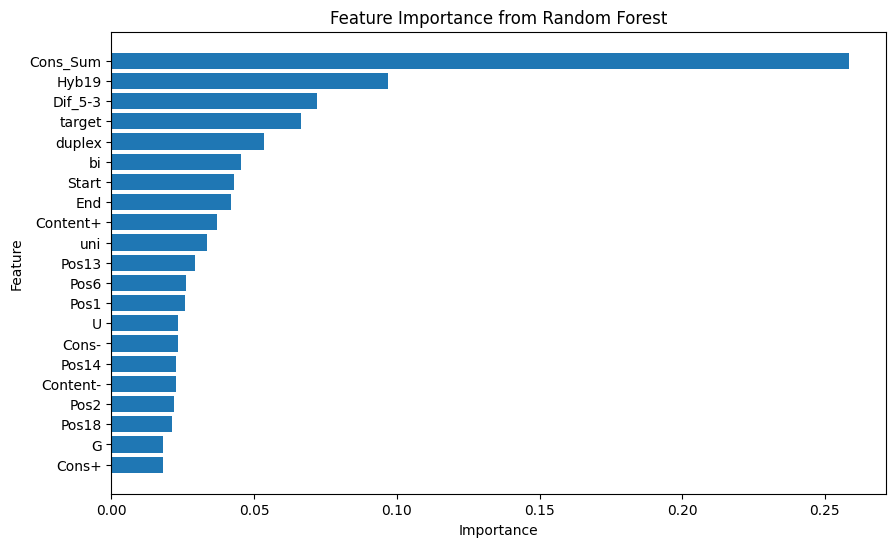

In [58]:

# Performing GridSearch with Cross-Validation
grid_search = GridSearchCV(estimator=random_forest_model, param_grid=param_grid, cv=5, n_jobs=1, scoring='r2')
grid_search.fit(X_train, y_train)

# Best estimator from grid search
best_model_rf = grid_search.best_estimator_
print("Best Parameters from Grid Search:", grid_search.best_params_)

# Cross-validation scores for the best model
cv_scores = cross_val_score(best_model_rf, X_train, y_train, cv=5, scoring='r2')
print("Cross-Validation R-squared Scores:", cv_scores)
print("Mean Cross-Validation R-squared Score:", np.mean(cv_scores))

# Making predictions on the test set
y_pred = best_model_rf.predict(X_test)

# Evaluating the model using suitable metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Displaying the metrics
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)

# Feature Importance Analysis
# Using the built-in feature importances from the Random Forest model
importances = best_model_rf.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plotting feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from Random Forest')
plt.gca().invert_yaxis()
plt.show()

- *Counterfactual Explanation*:
  - Counterfactual Explanations
Counterfactual explanations provide examples that show how slight changes in input features can lead to different predictions. This helps understand the decision boundaries of the Random Forest model and gives actionable insights.

In [ ]:
!pip install scikit-learn numpy==1.21.6 alibi

# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from alibi.explainers import KernelShap, Counterfactual
import matplotlib.pyplot as plt

# Counterfactual Explanation using Alibi
# Defining the Counterfactual explainer
cf = Counterfactual(best_model_rf.predict, shape=(1, X_train.shape[1]), target_proba=0.5, tol=0.1, lam_init=0.1, max_iter=1000,
                    max_lam_steps=10, learning_rate_init=0.1, feature_range=(X_train.min().values, X_train.max().values))

# Choosing an instance from the test set to generate a counterfactual for
instance = X_test.iloc[0].values.reshape(1, -1)

# Generating the counterfactual
explanation = cf.explain(instance)

# Displaying the results of the counterfactual explanation
print("Counterfactual Instance:")
print(explanation.cf['X'])

# Comparing original instance with counterfactual
print("Original Instance:")
print(instance)

print("Counterfactual Explanation Summary:")
print(explanation.cf['X'] - instance)

##### SHAP (SHapley Additive exPlanations): Random Forest
SHAP values provide a unified approach to explaining the output of machine learning models. It is a model-agnostic explainability technique based on game theory, which assigns an importance value to each feature for individual predictions. It provides insights into how different features contribute positively or negatively to a given prediction, making it ideal for regression problems such as this one

In [ ]:
!pip install scikit-learn numpy==1.21.6 alibi

# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from alibi.explainers import KernelShap
import matplotlib.pyplot as plt

# SHAP Values for Explainability using Alibi
# Using KernelShap from Alibi to determine the contribution of each feature to the prediction
explainer = KernelShap(best_model_rf.predict, X_train)
explainer.fit(X_train, n_samples=100)
shap_values = explainer.explain(X_test.values)

# Plotting SHAP summary to visualize feature contributions
plt.figure(figsize=(10, 6))
plt.title('SHAP Summary Plot using Alibi')
plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.barh(feature_importance_df['Feature'], np.mean(np.abs(shap_values.shap_values), axis=0))
plt.gca().invert_yaxis()
plt.show()


#### SVM Model

In [64]:
# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt


# Selecting numeric features and the target variable for regression analysis
data_features = cleaned_data.select_dtypes(include=['number']).drop(columns=['Activity'])
target = cleaned_data['Activity']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_features, target, test_size=0.2, random_state=42)

# Defining the SVM model for regression
svm_model = SVR()

# Defining the parameter grid for cross-validation
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

# Performing GridSearch with Cross-Validation
grid_search = GridSearchCV(estimator=svm_model, param_grid=param_grid, cv=5, n_jobs=1, scoring='r2')
grid_search.fit(X_train, y_train)

# Best estimator from grid search
best_model_svm = grid_search.best_estimator_
print("Best Parameters from Grid Search:", grid_search.best_params_)

# Cross-validation scores for the best model
cv_scores = cross_val_score(best_model_svm, X_train, y_train, cv=5, scoring='r2')
print("Cross-Validation R-squared Scores:", cv_scores)
print("Mean Cross-Validation R-squared Score:", np.mean(cv_scores))

# Making predictions on the test set
y_pred = best_model_svm.predict(X_test)

# Evaluating the model using suitable metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Displaying the metrics
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)


KeyboardInterrupt: 

In [ ]:

# Feature Importance Analysis
# Using the coefficients of the SVM model for feature importance analysis (only applicable for linear kernel)
if best_model_svm.kernel == 'linear':
    importances = np.abs(best_model_svm:.coef_).flatten()
    feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

    # Plotting feature importance
    plt.figure(figsize=(10, 6))
    plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.title('Feature Importance from SVM with Linear Kernel')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("Feature importance is not available for non-linear kernels.")

### Enrich dataset to use on the best models

In [80]:

# Dropping identifier columns ('Sequence', 'Target seq', 'Start', 'End')
cleaned_data = df_v2.drop(columns=[ 'Target seq'])



def get_kmers(sequence, k=3):
    return ["".join(sequence[i:i+k]) for i in range(len(sequence) - k + 1)]

cleaned_data['3_mers'] = cleaned_data['Sequence'].apply(lambda x: " ".join(get_kmers(x, k=3)))

from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
kmer_features = vectorizer.fit_transform(cleaned_data['3_mers'])

# Converting to DataFrame and concatenating with original data
kmer_df = pd.DataFrame(kmer_features.toarray(), columns=vectorizer.get_feature_names_out())
cleaned_data = pd.concat([cleaned_data.reset_index(drop=True), kmer_df], axis=1)
cleaned_data = cleaned_data.drop(columns=['3_mers'])
cleaned_data.head()



,Start,End,Sequence,G,U,bi,uni,duplex,Pos1,Pos2,...,ucg,ucu,uga,ugc,ugg,ugu,uua,uuc,uug,uuu
0,195,213,AUUAUCCACUGUUUUUGGA,3,9,-7.0,-1.9,-28.1,-1.1,-0.9,...,0,0,0,0,1,1,1,0,1,3
1,197,215,AAAUUAUCCACUGUUUUUG,2,9,-0.7,0.0,-24.2,-0.9,-0.9,...,0,0,0,0,0,1,1,0,1,3
2,199,217,CAAAAUUAUCCACUGUUUU,1,8,-1.5,0.0,-24.2,-2.1,-0.9,...,0,0,0,0,0,1,1,0,0,2
3,201,219,CACAAAAUUAUCCACUGUU,1,6,-0.6,0.0,-26.7,-2.1,-2.2,...,0,0,0,0,0,1,1,0,0,0
4,203,221,GCCACAAAAUUAUCCACUG,2,4,-0.1,0.0,-30.3,-3.4,-3.3,...,0,0,0,0,0,0,1,0,0,0


In [81]:
# Dropping identifier columns ('Sequence', 'Target seq', 'Start', 'End')
cleaned_data = cleaned_data.drop(columns=['Sequence'])



# Selecting numeric features and the target variable for regression analysis
data_features = cleaned_data.select_dtypes(include=['number']).drop(columns=['Activity'])
target = cleaned_data['Activity']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_features, target, test_size=0.2, random_state=42)

# Defining the Random Forest model for continuous features
random_forest_model = RandomForestRegressor(random_state=42, criterion='squared_error')

# Defining the parameter grid for cross-validation
param_grid = {
    'n_estimators': [50, 100, 200, 500],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

In [82]:
cleaned_data.head()

,Start,End,G,U,bi,uni,duplex,Pos1,Pos2,Pos6,...,ucg,ucu,uga,ugc,ugg,ugu,uua,uuc,uug,uuu
0,195,213,3,9,-7.0,-1.9,-28.1,-1.1,-0.9,-3.3,...,0,0,0,0,1,1,1,0,1,3
1,197,215,2,9,-0.7,0.0,-24.2,-0.9,-0.9,-1.1,...,0,0,0,0,0,1,1,0,1,3
2,199,217,1,8,-1.5,0.0,-24.2,-2.1,-0.9,-0.9,...,0,0,0,0,0,1,1,0,0,2
3,201,219,1,6,-0.6,0.0,-26.7,-2.1,-2.2,-0.9,...,0,0,0,0,0,1,1,0,0,0
4,203,221,2,4,-0.1,0.0,-30.3,-3.4,-3.3,-0.9,...,0,0,0,0,0,0,1,0,0,0


Best Parameters from Grid Search: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Cross-Validation R-squared Scores: [0.30642179 0.26102379 0.43151999 0.46667902 0.21870023]
Mean Cross-Validation R-squared Score: 0.33686896474182265
Mean Squared Error (MSE): 618.5638288632513
Mean Absolute Error (MAE): 20.206344257499318
R-squared (R2): 0.31333076442914176


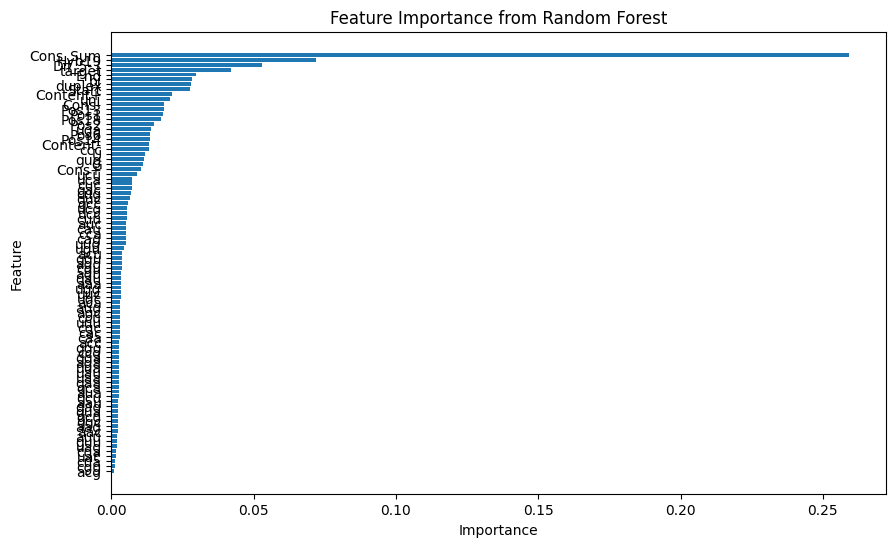

In [83]:

# Performing GridSearch with Cross-Validation
grid_search = GridSearchCV(estimator=random_forest_model, param_grid=param_grid, cv=5, n_jobs=1, scoring='r2')
grid_search.fit(X_train, y_train)

# Best estimator from grid search
best_model_rf = grid_search.best_estimator_
print("Best Parameters from Grid Search:", grid_search.best_params_)

# Cross-validation scores for the best model
cv_scores = cross_val_score(best_model_rf, X_train, y_train, cv=5, scoring='r2')
print("Cross-Validation R-squared Scores:", cv_scores)
print("Mean Cross-Validation R-squared Score:", np.mean(cv_scores))

# Making predictions on the test set
y_pred = best_model_rf.predict(X_test)

# Evaluating the model using suitable metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Displaying the metrics
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)

# Feature Importance Analysis
# Using the built-in feature importances from the Random Forest model
importances = best_model_rf.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plotting feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance from Random Forest')
plt.gca().invert_yaxis()
plt.show()

### Deep Neural Network

In [66]:
!pip install scikit-learn numpy==1.21.6 tensorflow

# Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Dropping identifier columns ('Sequence', 'Target seq', 'Start', 'End')
cleaned_data = df_v2.drop(columns=['Sequence', 'Target seq', 'Start', 'End'])

# Selecting numeric features and the target variable for regression analysis
data_features = cleaned_data.select_dtypes(include=['number']).drop(columns=['Activity'])
target = cleaned_data['Activity']

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_features, target, test_size=0.2, random_state=42)

# Reshaping the data for LSTM input (LSTM expects 3D data: [samples, timesteps, features])
X_train_lstm = np.expand_dims(X_train.values, axis=1)
X_test_lstm = np.expand_dims(X_test.values, axis=1)

# Defining a simple LSTM model
model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(1))

# Compiling the model
model.compile(optimizer='adam', loss='mse')

# Training the model
model.fit(X_train_lstm, y_train, epochs=20, batch_size=32, validation_data=(X_test_lstm, y_test), verbose=1)

# Making predictions on the test set
y_pred = model.predict(X_test_lstm)

# Evaluating the model using suitable metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Displaying the metrics
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-squared (R2):", r2)

# Feature Importance Analysis
# Note: LSTMs do not provide feature importances directly. Instead, we can use techniques like SHAP or permutation importance for interpretability.


Defaulting to user installation because normal site-packages is not writeable
     ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/590.6 MB 4.0 MB/s eta 0:02:26^C
     ╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/590.6 MB 4.0 MB/s eta 0:02:25
ERROR: Operation cancelled by user


2024-10-14 10:50:15.922249: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-14 10:50:15.931703: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-14 10:50:15.994838: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-14 10:50:16.058898: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-14 10:50:16.128450: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

RuntimeError: module compiled against API version 0x10 but this version of numpy is 0xe

RuntimeError: module compiled against API version 0x10 but this version of numpy is 0xe

RuntimeError: module compiled against API version 0x10 but this version of numpy is 0xe

SystemError: initialization of _pywrap_checkpoint_reader raised unreported exception

- *Counterfactual Explanation*: small LSTM model
  - Counterfactual Explanations
Counterfactual explanations provide examples that show how slight changes in input features can lead to different predictions. This helps understand the decision boundaries of the Random Forest model and gives actionable insights.

In [ ]:

# Counterfactual Explanation using Alibi
# Defining the Counterfactual explainer
from alibi.explainers import Counterfactual
cf = Counterfactual(model.predict, shape=(1, X_train.shape[1]), target_proba=0.5, tol=0.1, lam_init=0.1, max_iter=1000,
                    max_lam_steps=10, learning_rate_init=0.1, feature_range=(X_train.min().values, X_train.max().values))

# Choosing an instance from the test set to generate a counterfactual for
instance = X_test.iloc[0].values.reshape(1, -1)

# Generating the counterfactual
explanation = cf.explain(instance)

# Displaying the results of the counterfactual explanation
print("Counterfactual Instance:")
print(explanation.cf['X'])

# Comparing original instance with counterfactual
print("Original Instance:")
print(instance)

print("Counterfactual Explanation Summary:")
print(explanation.cf['X'] - instance)

#### Feature Scaling

In [93]:
# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on the entire dataset and transform
X_scaled = scaler.fit_transform(X)

#### Model 1 - Neural Network Sequential Model - linear stack of layers


- Linear stack of layers where each layer has one input and one output. This model consists of five layers: three dense (fully connected) layers and two dropout layers
- Explanation: 
  - 1. Dense(64, activation='relu', input_shape=(X_train.shape[1],))
Layer Type: Dense (Fully Connected Layer)
Number of Units: 64
This layer contains 64 neurons. Each neuron takes input from the previous layer and has a weighted connection to each input feature.
Activation Function: 'relu' (Rectified Linear Unit)
The ReLU activation function is used to add non-linearity to the model, allowing it to learn complex relationships. ReLU outputs the input value directly if it's positive, otherwise, it outputs zero. This helps mitigate the vanishing gradient problem often encountered during training.
Input Shape: input_shape=(X_train.shape[1],)
This specifies the shape of the input data, which is required only for the first layer. It takes the number of features as input, which is X_train.shape[1].
  - 2. Dropout(0.2)
Layer Type: Dropout Layer
Dropout Rate: 0.2
Dropout is a regularization technique used to prevent overfitting. It randomly sets 20% of the neurons in the previous layer to zero during each training iteration. This helps ensure that the model does not become too reliant on particular neurons, making it more robust.
  - 3. Dense(64, activation='relu')
Layer Type: Dense Layer
Number of Units: 64
This layer contains 64 neurons similar to the first layer.
Activation Function: 'relu'
Again, ReLU activation is used to add non-linearity to the model.
  - 4. Dropout(0.2)
Layer Type: Dropout Layer
Dropout Rate: 0.2
This dropout layer again sets 20% of the neurons in the previous layer to zero during training to prevent overfitting and help the model generalize better.
  - 5. Dense(1, activation='linear')
Layer Type: Dense Layer
Number of Units: 1
This layer has 1 output neuron. It is the output layer of the network, meaning that it provides the final output of the model.
Activation Function: 'linear'
The linear activation function is used, meaning that no transformation is applied to the output. This is suitable for regression tasks, where the goal is to predict a continuous value.

In [ ]:
# Define the model architecture
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='linear')  # Output layer for regression
])

# Display the model's architecture
model.summary()

In [96]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_squared_error']
)

In [ ]:
# Define Early Stopping callback
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
   validation_data=(X_val, y_val),# use Validdation data separated from Test data
    callbacks=[early_stop],
    verbose=1
)

In [ ]:
# Evaluate on test data
test_loss, test_mse = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Mean Squared Error (MSE): {test_mse:.4f}")

# Predict on test data
y_pred = model.predict(X_test).flatten()

# Calculate additional metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Test R-squared (R²): {r2:.4f}")

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(history.history['mean_squared_error'], label='Training MSE')
plt.plot(history.history['val_mean_squared_error'], label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('Training and Validation MSE Over Epochs')
plt.legend()
plt.show()

##### SHAP (SHapley Additive exPlanations) for the Deep Neural Network sequential model

Explanation:
DeepExplainer is specifically designed for deep learning models (such as Keras models) to provide explanations for predictions.
shap_values are calculated for the test set, which represent the contributions of each feature to the model's prediction.
The summary plot is used to visualize the global feature importance, helping us understand which features influence the model the most.

In [ ]:
import shap
import matplotlib.pyplot as plt

# Create the SHAP explainer using DeepExplainer for the deep learning model
explainer = shap.DeepExplainer(model, X_train)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test)

# Generate the SHAP summary plot
shap.summary_plot(shap_values, X_test, feature_names=X_train.columns)


##### Lime (Local Interpretable Model-agnostic Explanations) for the Deep Neural Network sequential model

Explanation:
LimeTabularExplainer is used to create an explainer object for the deep learning model:

Training Data (X_train.values): This helps LIME understand the distribution of the features.
Feature Names (X_train.columns): Makes the explanations more interpretable.
Class Names: Specifies that the target value is gene silencing activity.
Mode: Set to 'regression' because we're working with a regression problem.
Explain a Sample:

Choose a sample from the test set (sample_index).
The LIME explainer approximates the model prediction for that specific sample by generating a local linear approximation.
The predict function (lambda x: model.predict(x).flatten()) uses the trained model to make predictions.
Show Explanation:

The explanation is displayed directly in the notebook, providing a table of feature contributions.
HTML Save: Optionally save the explanation to an HTML file to view or share later.

In [ ]:
import lime
import lime.lime_tabular

# Create a LIME explainer object for tabular data
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns,
    class_names=['Gene Silencing Activity'],
    mode='regression'
)

# Choose a sample from the test set to explain
sample_index = 0  # Index of the sample in the test set you want to explain
sample = X_test.iloc[sample_index]

# Generate the explanation for the chosen sample
explanation = explainer.explain_instance(
    data_row=sample,
    predict_fn=lambda x: model.predict(x).flatten()
)

# Display the explanation in the notebook
explanation.show_in_notebook(show_table=True)

# Optional: Save the explanation as an HTML file
explanation.save_to_file('lime_explanation.html')


##### ( Choose a not agnostic explanation?)

#### Other more standard deep learning model?